# 3. Business Cycles

## 3.1. Overview

In this chapter we review empirical aspects of business cycles, which are fluctuations in economic activity over time. These include expansions (also called booms) and retractions (also called recessions).

For this study, we will use economic indicators from the World Bank and Federal Reserve Economic Data (FRED).

First we install some additional packages.

In [1]:
!pip install wbgapi
!pip install pandas-datareader

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [wbgapi]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.6/8.6 MB 35.0 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 876.3/876.3 kB 16.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [pandas-datareader]pandas-datareader]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


Next we'll import packages used in this notebook, along with perfoming some initial setup.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import datetime
import wbgapi as wb
import pandas_datareader.data as web

# Set graphical parameters
cycler = plt.cycler(
    linestyle=["-", "-.", "--", ":"],
    color=["#377eb8", "#ff7f00", "#4daf4a", "#ff334f"],
)
plt.rc("axes", prop_cycle=cycler)

# The cutoff date for the data we fetch below.
# To freeze the data for a reproducible build, replace this with a
# fixed date such as datetime.datetime(2024, 12, 31).
end_date = datetime.datetime.now()

## 3.2. Data Acquisition

We will use the World Banks data API `wbgapi` and `pandas_datareader` to pull data.

We can use `wb.series.info` with the argument `q` to query available data from the [World Bank](https://www.worldbank.org/ext/en/home).

For example, let’s retrieve the GDP growth data ID to query GDP growth data.

In [ ]:
wb.series.info(q="GDP growth")

id,value
NY.GDP.MKTP.KD.ZG,GDP growth (annual %)
,1 elements


We can now use this series ID to obtain the actual dataframe.

In [ ]:
gdp_growth = wb.data.DataFrame(
    "NY.GDP.MKTP.KD.ZG", ["USA", "ARG", "GBR", "GRC", "JPN"], labels=True
)
gdp_growth

,Country,YR1960,YR1961,YR1962,YR1963,YR1964,YR1965,YR1966,YR1967,YR1968,...,YR2016,YR2017,YR2018,YR2019,YR2020,YR2021,YR2022,YR2023,YR2024,YR2025
economy,,,,,,,,,,,,,,,,,,,,,
JPN,Japan,NaN,12.043536,8.908973,8.473642,11.676708,5.819708,10.638562,11.082142,12.882468,...,0.704986,1.623451,0.834144,-0.308497,-4.283279,3.564195,1.331648,0.720785,-0.240084,1.193113
GRC,Greece,NaN,13.203839,0.364812,11.844867,9.409677,10.768011,6.494501,5.669486,7.203718,...,-0.031795,1.473125,2.064672,2.277181,-9.196231,8.654498,5.521986,2.135911,2.086574,2.073069
GBR,United Kingdom,NaN,2.701314,1.098696,4.859545,5.594811,2.130333,1.567450,2.775738,5.472693,...,2.206520,3.023222,1.551331,1.256299,-10.047897,8.543112,5.149704,0.271650,1.080277,1.388442
ARG,Argentina,NaN,5.427843,-0.852022,-5.308197,10.130298,10.569433,-0.659726,3.191997,4.822501,...,-2.080328,2.818503,-2.617396,-2.000861,-9.900485,10.441812,6.020745,-1.855788,-1.342931,4.367333
USA,United States,NaN,2.300000,6.100000,4.400000,5.800000,6.400000,6.500000,2.500000,4.800000,...,1.819451,2.457622,2.966505,2.583825,-2.081376,6.152022,2.524214,2.934363,2.793187,2.161382


We can also examine the series metadata to learn more about the series.

In [ ]:
wb.series.metadata.get("NY.GDP.MKTP.KD.ZG")

========
Series: NY.GDP.MKTP.KD.ZG

Aggregationmethod: Weighted average
--------
Dataset: WB_WDI
--------
Developmentrelevance: This indicator is related to the national accounts, which are critical for understanding and managing a country's economy. They provide a framework for the analysis of economic performance. National accounts are the basis for estimating the Gross Domestic Product (GDP) and Gross National Income (GNI), which are the most widely used indicator of economic performance. They are essential for government policymakers, providing the data needed to design and assess fiscal and monetary policies; and are also used by businesses and investors to assess the economic climate and make investment decisions. NAS enable comparison between economies, which is crucial for international trade, investment decisions, and economic competitiveness. More specifically, this indicator is related to national accounts aggregates. Gross Domestic Product (GDP), Gross National Income (GNI), and other aggregates provide a snapshot of the size and health of an economy by measuring the total economic activity within a country. They can thus be used by policymakers to design and implement economic policies, as they reflect the overall economic performance and can indicate the need for intervention in certain areas. Aggregates also allow for comparisons between different economies, which can be useful for trade negotiations, investment decisions, and economic benchmarking. By examining aggregates over time, economists and analysts can identify trends, cycles, and potential areas of concern within an economy, and investors can use national accounts aggregates to assess the potential risks and returns of investing in a particular country. Overall, national accounts aggregates are fundamental tools for economic analysis, policy formulation, and decision-making at both the national and international levels.
--------
IndicatorName: GDP (annual % growth)
--------
License_Type: CC BY-4.0
--------
License_URL: https://datacatalog.worldbank.org/public-licenses#cc-by
--------
Limitationsandexceptions: Each industry's contribution to growth in the economy's output is measured by growth in the industry's value added. In principle, value added in constant prices can be estimated by measuring the quantity of goods and services produced in a period, valuing them at an agreed set of base year prices, and subtracting the cost of intermediate inputs, also in constant prices. This double-deflation method requires detailed information on the structure of prices of inputs and outputs.









In many industries, however, value added is extrapolated from the base year using single volume indexes of outputs or, less commonly, inputs. Particularly in the services industries, including most of government, value added in constant prices is often imputed from labor inputs, such as real wages or number of employees. In the absence of well defined measures of output, measuring the growth of services remains difficult.









Moreover, technical progress can lead to improvements in production processes and in the quality of goods and services that, if not properly accounted for, can distort measures of value added and thus of growth. When inputs are used to estimate output, as for nonmarket services, unmeasured technical progress leads to underestimates of the volume of output. Similarly, unmeasured improvements in quality lead to underestimates of the value of output and value added. The result can be underestimates of growth and productivity improvement and overestimates of inflation.









Informal economic activities pose a particular measurement problem, especially in developing countries, where much economic activity is unrecorded. A complete picture of the economy requires estimating household outputs produced for home use, sales in informal markets, barter exchanges, and illicit or deliberately unreported activities. The consistency and completeness o

## 3.3. GDP Growth Rate

Let's source our GDP growth rate data from the World Bank and clean it.

In [ ]:
# Use the series ID retrieved before
gdp_growth = wb.data.DataFrame(
    "NY.GDP.MKTP.KD.ZG", ["USA", "ARG", "GBR", "GRC", "JPN"], labels=True
)
gdp_growth = gdp_growth.set_index("Country")
gdp_growth.columns = gdp_growth.columns.str.replace("YR", "").astype(int)

gdp_growth

,1960,1961,1962,1963,1964,1965,1966,1967,1968,1969,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Country,,,,,,,,,,,,,,,,,,,,,
Japan,NaN,12.043536,8.908973,8.473642,11.676708,5.819708,10.638562,11.082142,12.882468,12.477895,...,0.704986,1.623451,0.834144,-0.308497,-4.283279,3.564195,1.331648,0.720785,-0.240084,1.193113
Greece,NaN,13.203839,0.364812,11.844867,9.409677,10.768011,6.494501,5.669486,7.203718,11.563668,...,-0.031795,1.473125,2.064672,2.277181,-9.196231,8.654498,5.521986,2.135911,2.086574,2.073069
United Kingdom,NaN,2.701314,1.098696,4.859545,5.594811,2.130333,1.567450,2.775738,5.472693,1.939138,...,2.206520,3.023222,1.551331,1.256299,-10.047897,8.543112,5.149704,0.271650,1.080277,1.388442
Argentina,NaN,5.427843,-0.852022,-5.308197,10.130298,10.569433,-0.659726,3.191997,4.822501,9.679526,...,-2.080328,2.818503,-2.617396,-2.000861,-9.900485,10.441812,6.020745,-1.855788,-1.342931,4.367333
United States,NaN,2.300000,6.100000,4.400000,5.800000,6.400000,6.500000,2.500000,4.800000,3.100000,...,1.819451,2.457622,2.966505,2.583825,-2.081376,6.152022,2.524214,2.934363,2.793187,2.161382


Next we write a function to construct plots for individual countries, taking into account historical recessions.

In [ ]:
def plot_series(
    data,
    country,
    ylabel,
    txt_pos,
    ax,
    g_params,
    b_params,
    t_params,
    ylim=15,
    baseline=0,
):
    """
    Plots a time series with recessions highlighted.

    Parameters
    ----------
    data : pd.DataFrame
        Data to plot
    country : str
        Name of the country to plot
    ylabel : str
        Label of the y-axis
    txt_pos : float
        Position of the recession labels
    y_lim : float
        Limit of the y-axis
    ax : matplotlib.axes._subplots.AxesSubplot
        Axes to plot on
    g_params : dict
        Parameters for the line
    b_params : dict
        Parameters for the recession highlights
    t_params : dict
        Parameters for the recession labels
    baseline : float, optional
        Dashed baseline on the plot, by default 0

    Returns
    -------
    ax : matplotlib.axes.Axes
        Axes with the plot.
    """

    ax.plot(data.loc[country], label=country, **g_params)

    # Highlight recessions
    ax.axvspan(1973, 1975, **b_params)
    ax.axvspan(1990, 1992, **b_params)
    ax.axvspan(2007, 2009, **b_params)
    ax.axvspan(2019, 2021, **b_params)
    if ylim != None:
        ax.set_ylim([-ylim, ylim])
    else:
        ylim = ax.get_ylim()[1]
    ax.text(1974, ylim + ylim * txt_pos, "Oil Crisis\n(1974)", **t_params)
    ax.text(1991, ylim + ylim * txt_pos, "1990s recession\n(1991)", **t_params)
    ax.text(2008, ylim + ylim * txt_pos, "GFC\n(2008)", **t_params)
    ax.text(2020, ylim + ylim * txt_pos, "Covid-19\n(2020)", **t_params)

    # Add a baseline for reference
    if baseline != None:
        ax.axhline(y=baseline, color="black", linestyle="--")
    ax.set_ylabel(ylabel)
    ax.legend()
    return ax


# Define graphical parameters
g_params = {"alpha": 0.7}
b_params = {"color": "grey", "alpha": 0.2}
t_params = {"color": "grey", "fontsize": 9, "va": "center", "ha": "center"}

We start by examining the US.

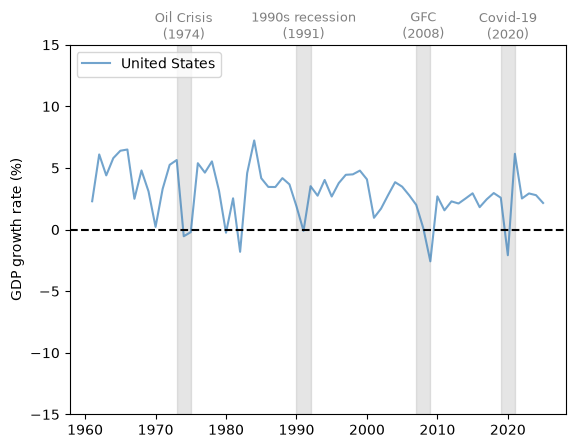

In [ ]:
fig, ax = plt.subplots()

country = "United States"
ylabel = "GDP growth rate (%)"
plot_series(gdp_growth, country, ylabel, 0.1, ax, g_params, b_params, t_params)
plt.show()

We see that GDP growth is typically positive, but appears to be trending down over time. This tells us that while US GDP is still typically growing, that growth is slowing down over time. The fluctuations in growth are also quite large overall.

Let's look at the UK next.

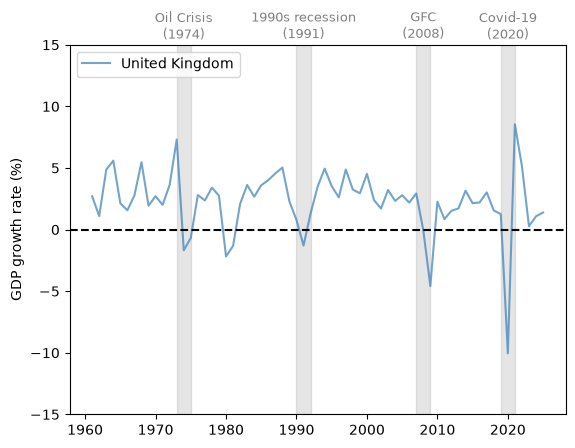

In [ ]:
fig, ax = plt.subplots()

country = "United Kingdom"
plot_series(gdp_growth, country, ylabel, 0.1, ax, g_params, b_params, t_params)
plt.show()

The UK exhibits a similar pattern to the US, with overall positive, but declining growth, and large variation. COVID-19 appear to have particularly severely affected UK GDP growth.

Next we consider Japan.

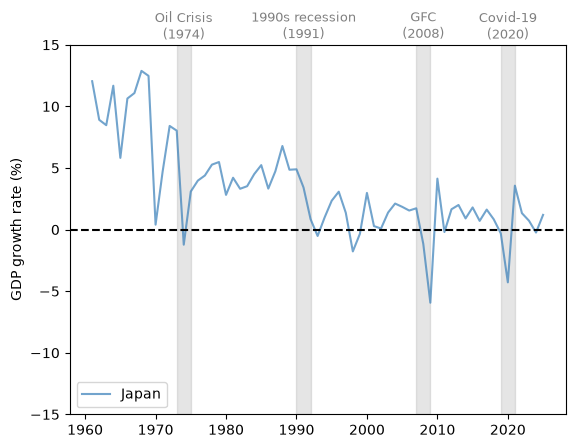

In [ ]:
fig, ax = plt.subplots()

country = "Japan"
plot_series(gdp_growth, country, ylabel, 0.1, ax, g_params, b_params, t_params)
plt.show()

We can see that Japan's growth was huge in the 60s and 70s, but declined after the oil crisis and never fully recovered to pre-recession levels after the 90s recession. Since then it has maintained moderately positive growth outside of reessions, but not nearly as large as it previously was.

Next we look at Greece.

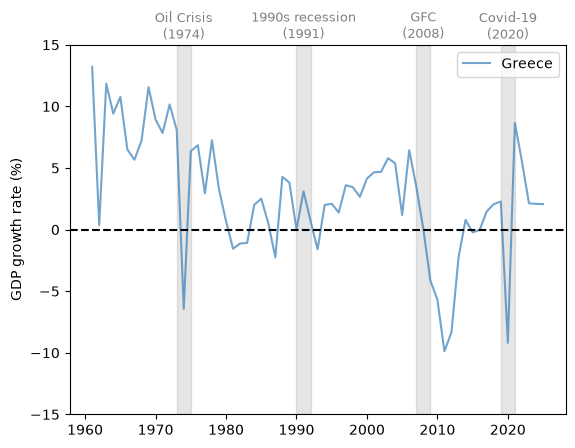

In [ ]:
fig, ax = plt.subplots()

country = "Greece"
plot_series(gdp_growth, country, ylabel, 0.1, ax, g_params, b_params, t_params)
plt.show()

The Greek Debt Crisis, which resulted in a large contraction of Greek GDP, can be seen around 2010.

Next we examine Argentina.

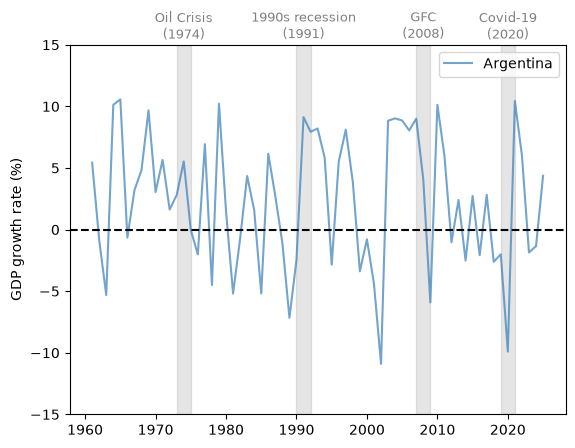

In [ ]:
fig, ax = plt.subplots()

country = "Argentina"
plot_series(gdp_growth, country, ylabel, 0.1, ax, g_params, b_params, t_params)
plt.show()

As we can see, Argentina's economy has been highly volatile, frequently fluctuating by 15-20% between expanding and contracting.

## 3.4. Unemployment

Another important indicator of business cycles is the unemployment rate. We use data from FRED and the Census Bureau to study the unemployment rate.

In [ ]:
start_date = datetime.datetime(1929, 1, 1)
hist_end_date = datetime.datetime(1942, 6, 1)

unrate_history = web.DataReader(
    "M0892AUSM156SNBR", "fred", start_date, hist_end_date
)
unrate_history.rename(columns={"M0892AUSM156SNBR": "UNRATE"}, inplace=True)

start_date = datetime.datetime(1948, 1, 1)

unrate = web.DataReader("UNRATE", "fred", start_date, end_date)

We now plot the unemployment rate of the US from 1929 to the present with recessions defined by the NBER.

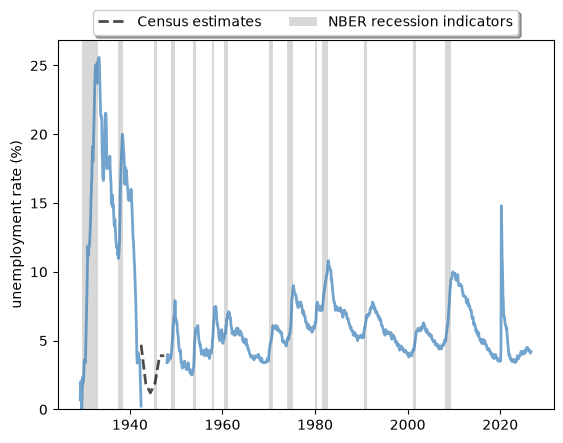

In [ ]:
# We use the census bureau's estimate for the unemployment rate
# between 1942 and 1948
years = [datetime.datetime(year, 6, 1) for year in range(1942, 1948)]
unrate_census = [4.7, 1.9, 1.2, 1.9, 3.9, 3.9]

unrate_census = {"DATE": years, "UNRATE": unrate_census}
unrate_census = pd.DataFrame(unrate_census)
unrate_census.set_index("DATE", inplace=True)

# Obtain the NBER-defined recession periods
start_date = datetime.datetime(1929, 1, 1)

nber = web.DataReader("USREC", "fred", start_date, end_date)

fig, ax = plt.subplots()

ax.plot(
    unrate_history, **g_params, color="#377eb8", linestyle="-", linewidth=2
)
ax.plot(
    unrate_census,
    **g_params,
    color="black",
    linestyle="--",
    label="Census estimates",
    linewidth=2,
)
ax.plot(unrate, **g_params, color="#377eb8", linestyle="-", linewidth=2)

# Draw gray boxes according to NBER recession indicators
ax.fill_between(
    nber.index,
    0,
    1,
    where=nber["USREC"] == 1,
    color="grey",
    edgecolor="none",
    alpha=0.3,
    transform=ax.get_xaxis_transform(),
    label="NBER recession indicators",
)
ax.set_ylim([0, ax.get_ylim()[1]])
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.1),
    ncol=3,
    fancybox=True,
    shadow=True,
)
ax.set_ylabel("unemployment rate (%)")

plt.show()

We notice two things:
1. Spikes in the unemployment rate appear highly correlated with recessions.
2. The unemployment spikes are asymmetrical. This shows that unemployment rises rapidly in a recession, followed by a slow, drawn out recovery.

## 3.5. Synchronization

Let's put what we've learned together, with a particular eye towards how the GDP growth rates of different country have changed similarly, e.g., around recessions.

In [ ]:
def plot_comparison(
    data,
    countries,
    ylabel,
    txt_pos,
    y_lim,
    ax,
    g_params,
    b_params,
    t_params,
    baseline=0,
):
    """
    Plot multiple series on the same graph

    Parameters
    ----------
    data : pd.DataFrame
        Data to plot
    countries : list
        List of countries to plot
    ylabel : str
        Label of the y-axis
    txt_pos : float
        Position of the recession labels
    y_lim : float
        Limit of the y-axis
    ax : matplotlib.axes._subplots.AxesSubplot
        Axes to plot on
    g_params : dict
        Parameters for the lines
    b_params : dict
        Parameters for the recession highlights
    t_params : dict
        Parameters for the recession labels
    baseline : float, optional
        Dashed baseline on the plot, by default 0

    Returns
    -------
    ax : matplotlib.axes.Axes
        Axes with the plot.
    """

    # Allow the function to go through more than one series
    for country in countries:
        ax.plot(data.loc[country], label=country, **g_params)

    # Highlight recessions
    ax.axvspan(1973, 1975, **b_params)
    ax.axvspan(1990, 1992, **b_params)
    ax.axvspan(2007, 2009, **b_params)
    ax.axvspan(2019, 2021, **b_params)
    if y_lim != None:
        ax.set_ylim([-y_lim, y_lim])
    ylim = ax.get_ylim()[1]
    ax.text(1974, ylim + ylim * txt_pos, "Oil Crisis\n(1974)", **t_params)
    ax.text(1991, ylim + ylim * txt_pos, "1990s recession\n(1991)", **t_params)
    ax.text(2008, ylim + ylim * txt_pos, "GFC\n(2008)", **t_params)
    ax.text(2020, ylim + ylim * txt_pos, "Covid-19\n(2020)", **t_params)
    if baseline != None:
        ax.hlines(
            y=baseline,
            xmin=ax.get_xlim()[0],
            xmax=ax.get_xlim()[1],
            color="black",
            linestyle="--",
        )
    ax.set_ylabel(ylabel)
    ax.legend()
    return ax


# Define graphical parameters
g_params = {"alpha": 0.7}
b_params = {"color": "grey", "alpha": 0.2}
t_params = {"color": "grey", "fontsize": 9, "va": "center", "ha": "center"}

# Obtain GDP growth rate for a list of countries
gdp_growth = wb.data.DataFrame(
    "NY.GDP.MKTP.KD.ZG",
    ["CHN", "USA", "DEU", "BRA", "ARG", "GBR", "JPN", "MEX"],
    labels=True,
)
gdp_growth = gdp_growth.set_index("Country")
gdp_growth.columns = gdp_growth.columns.str.replace("YR", "").astype(int)

We first plot the GDP growth rate for the UK, the US, Germany, and Japan as examples of developed countries.

In [ ]:
# Plot the GDP growth rate for the UK, the US, Germany, and Japan as examples of developed economies.
fig, ax = plt.subplots()
countries = ["United Kingdom", "United States", "Germany", "Japan"]
ylabel = "GDP growth rate (%)"
plot_comparison(
    gdp_growth.loc[countries, 1962:],
    countries,
    ylabel,
    0.1,
    20,
    ax,
    g_params,
    b_params,
    t_params,
)
plt.show()

Next we use Brazil, China, Argentina, and Mexico as examples of developing economies.

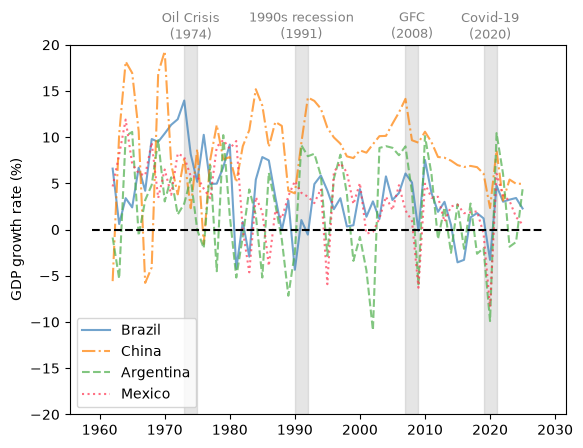

In [ ]:
fig, ax = plt.subplots()
countries = ["Brazil", "China", "Argentina", "Mexico"]
plot_comparison(
    gdp_growth.loc[countries, 1962:],
    countries,
    ylabel,
    0.1,
    20,
    ax,
    g_params,
    b_params,
    t_params,
)
plt.show()

Comparing the above plots, it appears that growth rates are synchronizing more during recessions in the 21st century as global economies become more interconnected. Additionally, developing economies generally appear to have much more volatile growth than developed economies.

Next we also examine the unemployment rate in the US, the UK, Japan, and France.

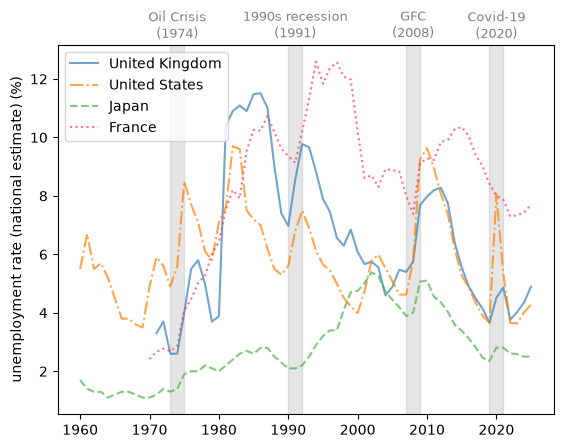

In [ ]:
unempl_rate = wb.data.DataFrame(
    "SL.UEM.TOTL.NE.ZS", ["USA", "FRA", "GBR", "JPN"], labels=True
)
unempl_rate = unempl_rate.set_index("Country")
unempl_rate.columns = unempl_rate.columns.str.replace("YR", "").astype(int)

fig, ax = plt.subplots()

countries = ["United Kingdom", "United States", "Japan", "France"]
ylabel = "unemployment rate (national estimate) (%)"
plot_comparison(
    unempl_rate,
    countries,
    ylabel,
    0.05,
    None,
    ax,
    g_params,
    b_params,
    t_params,
    baseline=None,
)
plt.show()

We can see that, despite some similarities around recessions, the recovery periods for all these countries is quite different, pointing to real differences in the recover from recessions in each country.

In particular, France appears to struggle with recoveries after recessions. The QuantEcon authors attribute this to strong French labor unions, which, while offering protections for existing workers, creates less flexibility in hiring terms in response to changing economic conditions, making the labor market less adaptable in post-recessionary periods.

Additionally, while Japan has lower GDP growth in the above plots, it also has lower unemployment rates, indicating a large degree of stability in the Japanese job market.

## 3.6. Leading Indicators and Correlated Factors

Leading indicators and correlating factors help us (and policy makers) understand the causes and effects of business cycles. We discuss these indicators and factors from three perspectives: consumption, production, and credit level.

### 3.6.1. Consumption

Consumption depends on consumers' confidence in their income, and overall economic performance in the future. One widely cited metric for consumer confidence is the [consumer sentiment index](https://fred.stlouisfed.org/series/UMCSENT), published by the University of Michigan. In the next plot we show the consumer sentiment index plotted against year-on-year changes to the [core consumer price index](https://fred.stlouisfed.org/series/CPILFESL) from 1978 to the present in the US.

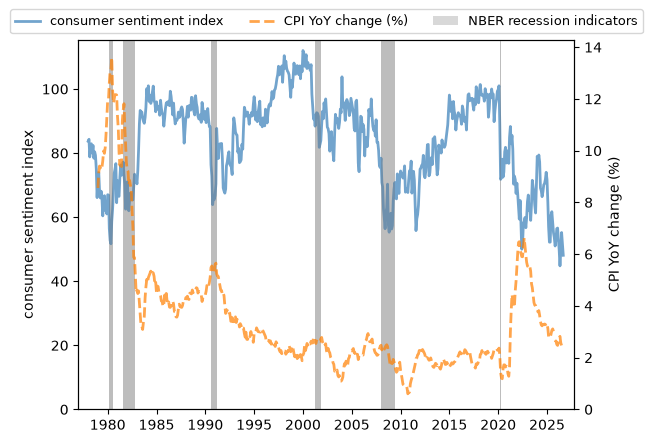

In [ ]:
start_date = datetime.datetime(1978, 1, 1)

# Limit the plot to a specific range
start_date_graph = datetime.datetime(1977, 1, 1)
end_date_graph = end_date + datetime.timedelta(days=365)

nber = web.DataReader("USREC", "fred", start_date, end_date)
consumer_confidence = web.DataReader("UMCSENT", "fred", start_date, end_date)

fig, ax = plt.subplots()
ax.plot(
    consumer_confidence,
    **g_params,
    color="#377eb8",
    linestyle="-",
    linewidth=2,
)
ax.fill_between(
    nber.index,
    0,
    1,
    where=nber["USREC"] == 1,
    color="grey",
    edgecolor="none",
    alpha=0.3,
    transform=ax.get_xaxis_transform(),
    label="NBER recession indicators",
)
ax.set_ylim([0, ax.get_ylim()[1]])
ax.set_ylabel("consumer sentiment index")

# Plot CPI on another y-axis
ax_t = ax.twinx()
inflation = (
    web.DataReader("CPILFESL", "fred", start_date, end_date).pct_change(12)
    * 100
)

# Add CPI on the legend without drawing the line again
ax_t.plot(
    2020,
    0,
    **g_params,
    linestyle="-",
    linewidth=2,
    label="consumer sentiment index",
)
ax_t.plot(
    inflation,
    **g_params,
    color="#ff7f00",
    linestyle="--",
    linewidth=2,
    label="CPI YoY change (%)",
)

ax_t.fill_between(
    nber.index,
    0,
    1,
    where=nber["USREC"] == 1,
    color="grey",
    edgecolor="none",
    alpha=0.3,
    transform=ax.get_xaxis_transform(),
    label="NBER recession indicators",
)
ax_t.set_ylim([0, ax_t.get_ylim()[1]])
ax_t.set_xlim([start_date_graph, end_date_graph])
ax_t.legend(loc="upper center", bbox_to_anchor=(0.5, 1.1), ncol=3, fontsize=9)
ax_t.set_ylabel("CPI YoY change (%)")
plt.show()

We can see that the consumer sentiment index generally drops before a recession, and rises during economic expansion. It also appears to be negatively correlated with the YoY CPI change.

### 3.6.2. Production

Production is typically correlated with recessions in the economy. However, it is not a leading indicator as the peak of contraction is delayed relative to consumer confidence and inflation. Here we plot the YoY industrial output changes in the US since 1919.

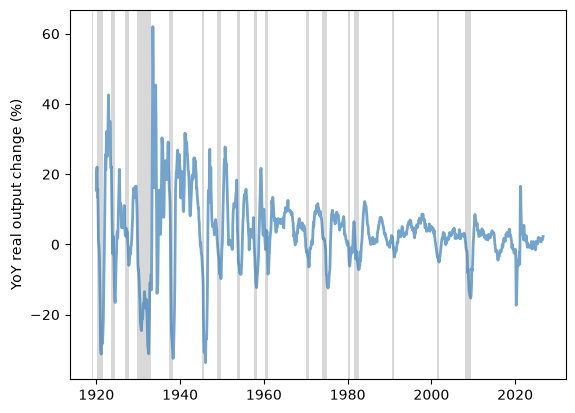

In [ ]:
start_date = datetime.datetime(1919, 1, 1)

nber = web.DataReader("USREC", "fred", start_date, end_date)
industrial_output = (
    web.DataReader("INDPRO", "fred", start_date, end_date).pct_change(12) * 100
)

fig, ax = plt.subplots()
ax.plot(
    industrial_output,
    **g_params,
    color="#377eb8",
    linestyle="-",
    linewidth=2,
    label="Industrial production index",
)
ax.fill_between(
    nber.index,
    0,
    1,
    where=nber["USREC"] == 1,
    color="grey",
    edgecolor="none",
    alpha=0.3,
    transform=ax.get_xaxis_transform(),
    label="NBER recession indicators",
)
ax.set_ylim([ax.get_ylim()[0], ax.get_ylim()[1]])
ax.set_ylabel("YoY real output change (%)")
plt.show()

### 3.6.3. Credit Level

Credit contractions often coincide with recessions, as lenders are more hesitant to take on additional risk, and borrowers are more hesitant to take on additional debt, driven by pessimistic outlooks on the future, and contracted economic activity.

Here we plot trends for domestic credit to the private sector by banks in the UK.

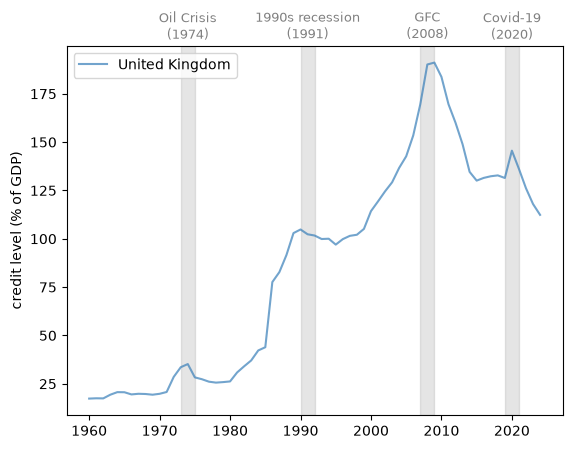

In [ ]:
private_credit = wb.data.DataFrame("FS.AST.PRVT.GD.ZS", ["GBR"], labels=True)
private_credit = private_credit.set_index("Country")
private_credit.columns = private_credit.columns.str.replace("YR", "").astype(
    int
)

fig, ax = plt.subplots()

countries = "United Kingdom"
ylabel = "credit level (% of GDP)"
ax = plot_series(
    private_credit,
    countries,
    ylabel,
    0.05,
    ax,
    g_params,
    b_params,
    t_params,
    ylim=None,
    baseline=None,
)
plt.show()

We can see that credit reises during expansions, and stagnates or even contracts during recessions.